# Analysis
## 01 - Einführung: Was ist Analysis?
Die Mathematik der Veränderung

Die **Analysis** (auch: Infinitesimalrechnung) ist eines der mächtigsten Werkzeuge der Mathematik. Sie wurde im 17. Jahrhundert unabhängig voneinander von **Isaac Newton** und **Gottfried Wilhelm Leibniz** entwickelt und ist heute die Grundlage für Physik, Ingenieurwesen, Wirtschaft, Informatik und vieles mehr.

Die zentrale Frage der Analysis: **Wie beschreibt man Veränderung mathematisch exakt?**

### Lernziele

Diese Reihe behandelt folgende Themen:

- **Was Analysis ist** und warum sie so wichtig ist
- **Grenzwerte** - die mathematische Grundlage (Wiederholung aus Funktionen)
- **Differentialrechnung** - Ableitungen, Steigungen, Kurvendiskussion
- **Integralrechnung** - Flächen, Stammfunktionen, der Hauptsatz

> **Hinweis:** Notebooks 07 und 08 (Partielle Ableitungen, Multivariate Kettenregel) gehen über den typischen Matura-Stoff hinaus und können bei Bedarf übersprungen werden.

---

### 1. Die drei Säulen der Analysis

Die Analysis besteht aus drei eng verbundenen Konzepten:

| Säule | Kernfrage | Werkzeug |
|-------|-----------|----------|
| **Grenzwerte** | Was passiert, wenn wir uns einem Wert *unendlich nah* annähern? | $\lim_{x \to a} f(x)$ |
| **Differentialrechnung** | Wie schnell ändert sich eine Funktion? Was ist die Steigung? | $f'(x) = \frac{df}{dx}$ |
| **Integralrechnung** | Wie groß ist die Fläche unter einer Kurve? Was ist das Gegenteil der Ableitung? | $\int f(x)\,dx$ |

Diese drei Konzepte sind eng miteinander verknüpft: Die Ableitung baut auf dem Grenzwertbegriff auf, und der **Hauptsatz der Analysis** stellt eine überraschende Verbindung her - Ableiten und Integrieren sind Umkehroperationen voneinander. Was genau das bedeutet, entfaltet sich schrittweise in den kommenden Notebooks.

#### Die große Idee

Viele Größen in der Natur verändern sich *ständig*. Ein Auto beschleunigt, die Temperatur schwankt, eine Population wächst. Die Analysis gibt uns die Sprache, um solche **kontinuierlichen Veränderungen** präzise zu beschreiben - und zwar nicht nur näherungsweise, sondern exakt.

Die folgende Visualisierung gibt einen ersten Eindruck der drei Konzepte an einem konkreten Beispiel. Sie wird am Ende dieser Reihe vollständig verständlich sein - noch nicht alles muss jetzt schon klar sein.

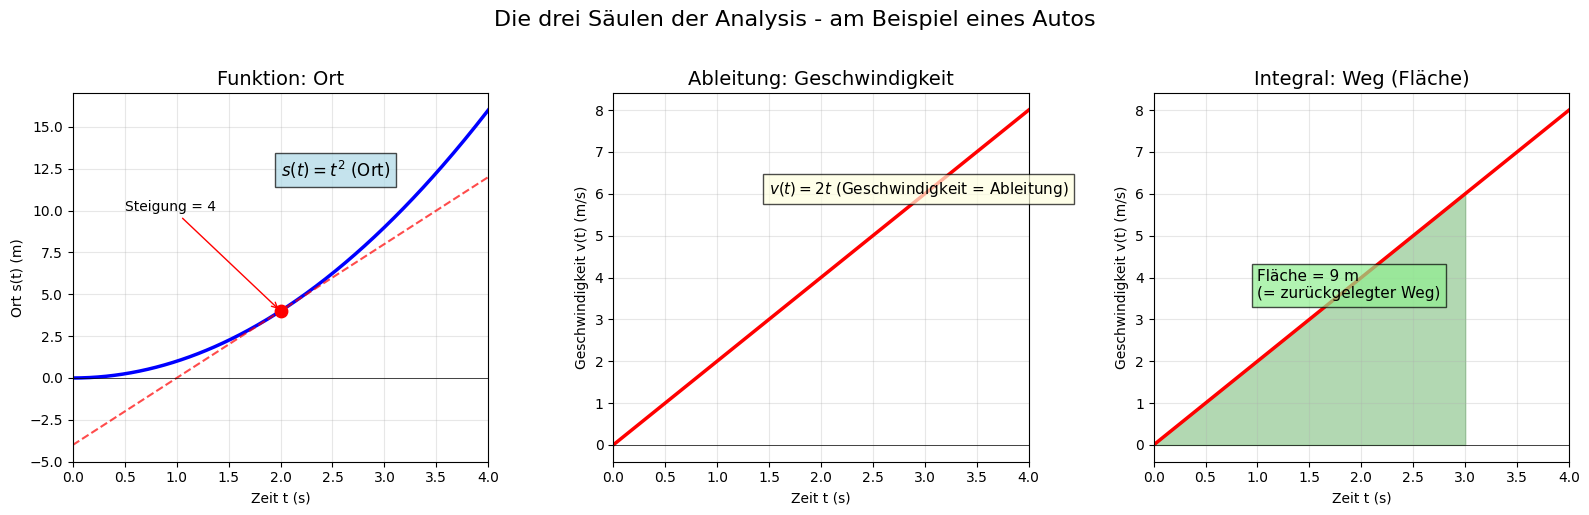

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# --- Die drei Säulen der Analysis auf einen Blick ---
# Beispiel: Auto fährt mit f(t) = t² Metern in t Sekunden

Einfuehrung_Config = {
    "funktion_label": "$s(t) = t^2$ (Ort)",
    "ableitung_label": "$v(t) = 2t$ (Geschwindigkeit = Ableitung)",
    "integral_label": "zurückgelegter Weg (Integral = Fläche)",
    "t_bereich": (0, 4),
    "figsize": (16, 5),
}

def visualisiere_analysis_ueberblick(config):
    """Zeigt die drei Säulen: Funktion, Ableitung, Integral."""
    t = np.linspace(*config["t_bereich"], 300)
    s = t**2           # Ortsfunktion
    v = 2*t            # Geschwindigkeit (Ableitung)

    fig, axes = plt.subplots(1, 3, figsize=config["figsize"])

    # --- Panel 1: Die Funktion ---
    axes[0].plot(t, s, color='blue', linewidth=2.5)
    axes[0].set_title("Funktion: Ort", fontsize=14)
    axes[0].set_xlabel("Zeit t (s)")
    axes[0].set_ylabel("Ort s(t) (m)")
    axes[0].text(2, 12, config["funktion_label"], fontsize=12,
                bbox=dict(facecolor='lightblue', alpha=0.7))
    axes[0].grid(True, alpha=0.3)

    # --- Panel 2: Die Ableitung (Steigung = Geschwindigkeit) ---
    axes[1].plot(t, v, color='red', linewidth=2.5)
    axes[1].set_title("Ableitung: Geschwindigkeit", fontsize=14)
    axes[1].set_xlabel("Zeit t (s)")
    axes[1].set_ylabel("Geschwindigkeit v(t) (m/s)")
    axes[1].text(1.5, 6, config["ableitung_label"], fontsize=11,
                bbox=dict(facecolor='lightyellow', alpha=0.7))
    axes[1].grid(True, alpha=0.3)

    # Tangente bei t=2 auf Panel 1 hinzufügen
    t_p = 2
    s_p = t_p**2
    m = 2 * t_p  # Steigung bei t=2
    tangente = m * (t - t_p) + s_p
    axes[0].plot(t, tangente, 'r--', linewidth=1.5, alpha=0.7)
    axes[0].scatter(t_p, s_p, color='red', s=80, zorder=5)
    axes[0].annotate(f"Steigung = {m}", xy=(t_p, s_p), xytext=(0.5, 10),
                    fontsize=10, arrowprops=dict(arrowstyle='->', color='red'))

    # --- Panel 3: Das Integral (Fläche = zurückgelegter Weg) ---
    t_fill = np.linspace(0, 3, 300)
    v_fill = 2 * t_fill
    axes[2].plot(t, v, color='red', linewidth=2.5)
    axes[2].fill_between(t_fill, 0, v_fill, color='green', alpha=0.3)
    axes[2].set_title("Integral: Weg (Fläche)", fontsize=14)
    axes[2].set_xlabel("Zeit t (s)")
    axes[2].set_ylabel("Geschwindigkeit v(t) (m/s)")

    # Flächenwert berechnen: ∫₀³ 2t dt = [t²]₀³ = 9
    flaeche = 3**2 - 0**2  # = 9m
    axes[2].text(1.0, 3.5, f"Fläche = {flaeche} m\n(= zurückgelegter Weg)", fontsize=11,
                bbox=dict(facecolor='lightgreen', alpha=0.7))
    axes[2].grid(True, alpha=0.3)

    for ax in axes:
        ax.set_xlim(*config["t_bereich"])
        ax.axhline(0, color='black', linewidth=0.5)

    plt.suptitle("Die drei Säulen der Analysis - am Beispiel eines Autos", fontsize=16, y=1.02)
    plt.tight_layout()
    plt.show()

visualisiere_analysis_ueberblick(Einfuehrung_Config)

### 2. Wozu braucht man Analysis?

Einige Beispiele, in denen Analysis unverzichtbar ist:

| Bereich | Anwendung | Analysis-Werkzeug |
|---------|-----------|-------------------|
| **Physik** | Bewegung, Kräfte, Energie | Ableitungen (Geschwindigkeit, Beschleunigung) |
| **Ingenieurwesen** | Optimierung von Formen, Materialien | Extremwertprobleme (Kurvendiskussion) |
| **Wirtschaft** | Gewinnmaximierung, Kostenfunktionen | Ableitung = Grenzkosten/Grenzertrag |
| **Medizin** | Medikamentenabbau im Körper | Differentialgleichungen (exp. Zerfall) |
| **Informatik / KI** | Maschinelles Lernen, neuronale Netze | Gradient Descent (partielle Ableitungen) |
| **Statistik** | Wahrscheinlichkeitsverteilungen | Integrale (Fläche unter der Verteilung) |

### 3. Voraussetzungen für diese Reihe

Bevor Du in die Analysis eintauchst, solltest Du sicher sein mit:
- **Funktionen** - Funktionsbegriff, Darstellungsformen, Graphen lesen 
- **Polynome** - Quadratische Funktionen, Parabeln
- **Exponential- und Logarithmusfunktionen** - $e^x$, $\ln(x)$ 
- **Trigonometrie** - $\sin$, $\cos$, $\tan$ 
- **Grenzwerte** - Grundlage in der Analysis

---

### 4. Roadmap: Übersicht der Notebooks

| # | Notebook | Thema |
|---|----------|-------|
| 01 | **Einführung** (dieses Notebook) | Was ist Analysis? Überblick und Motivation |
| 02 | **Ableitungen: Einführung** | Sekante → Tangente, Grenzwertdefinition, numerisch & symbolisch |
| 03 | **Ableitungsregeln** | Potenz-, Produkt-, Quotienten-, Kettenregel |
| 04 | **Höhere Ableitungen & Kurvendiskussion** | $f'$, $f''$, Extrema, Wendepunkte, vollständige Kurvenanalyse |
| 05 | **Integralrechnung: Einführung** | Stammfunktion, bestimmtes Integral, Hauptsatz |
| 06 | **Integrationsregeln & Anwendungen** | Regeln, Flächen, Volumina, Anwendungen |
| 07 | **Partielle Ableitungen** | Funktionen mehrerer Variablen, Gradient |
| 08 | **Multivariate Kettenregel & Gradient** | Kettenregel für $f(\mathbf{g}(\mathbf{x}))$, totales Differential, Jacobi-Matrix |

> **Hinweis:** Notebooks 07 und 08 gehen über den Matura-Stoff hinaus und können übersprungen werden.

### 5. Die zentrale Idee: Annäherung und Grenzwert

Die Analysis beruht auf einer einzigen, kraftvollen Grundidee: **Wir nähern uns dem Exakten durch das Approximierte an.**

Schon Archimedes (ca. 250 v. Chr.) nutzte dieses Prinzip, um Flächen unter Kurven zu berechnen - indem er sie mit immer kleineren Rechtecken füllte. Je mehr Rechtecke, desto kleiner der Fehler. Was im Grenzfall entsteht, ist der exakte Flächeninhalt. Dieselbe Logik steckt auch hinter der Ableitung: Man nähert die Steigung einer Kurve durch immer kürzere Geraden an und fragt, welchen Wert die Steigung im Grenzfall annimmt.

Das ist der rote Faden der gesamten Analysis: *Annäherung → Grenzwert → exakter Wert*.

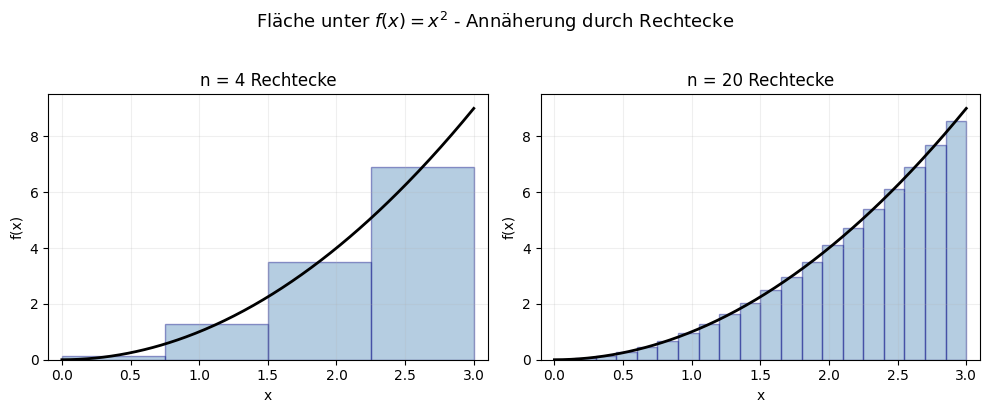

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# --- Annäherung an eine Kurve durch Rechtecke ---
# Nur zur Illustration der Grundidee; volle Behandlung in Notebook 05

Annaeherung_Config = {
    "funktion": lambda x: x**2,
    "label": "$f(x) = x^2$",
    "bereich": (0, 3),
    "n_werte": [4, 20],
    "figsize": (10, 4),
}

def visualisiere_annaeherung(config):
    """Zeigt die Idee: je mehr Rechtecke, desto genauer die Annäherung."""
    f = config["funktion"]
    a, b = config["bereich"]
    x_smooth = np.linspace(a, b, 300)

    fig, axes = plt.subplots(1, 2, figsize=config["figsize"])

    for idx, n in enumerate(config["n_werte"]):
        ax = axes[idx]
        dx = (b - a) / n
        x_links = np.linspace(a, b - dx, n)

        for xi in x_links:
            hoehe = f(xi + dx / 2)
            rect = plt.Rectangle((xi, 0), dx, hoehe, fill=True,
                                  facecolor='steelblue', edgecolor='navy', alpha=0.4)
            ax.add_patch(rect)

        ax.plot(x_smooth, f(x_smooth), color='black', linewidth=2)
        ax.set_title(f"n = {n} Rechtecke", fontsize=12)
        ax.set_xlim(a - 0.1, b + 0.1)
        ax.set_ylim(0, f(b) + 0.5)
        ax.grid(True, alpha=0.2)
        ax.axhline(0, color='black', linewidth=0.5)
        ax.set_xlabel("x")
        ax.set_ylabel("f(x)")

    fig.suptitle(f"Fläche unter {config['label']} - Annäherung durch Rechtecke",
                 fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()

visualisiere_annaeherung(Annaeherung_Config)

Mit mehr Rechtecken wird die Annäherung deutlich besser - und im Grenzwert unendlich vieler, unendlich schmaler Rechtecke ergibt sich die exakte Fläche. Wie das mathematisch funktioniert, ist Thema von Notebook 05.

---

## Zusammenfassung

| Konzept | Kernaussage |
|---------|-------------|
| **Analysis** | Mathematik der Veränderung: Grenzwerte, Ableitungen, Integrale |
| **Ableitung** | Misst, wie schnell sich etwas ändert (Steigung, Momentangeschwindigkeit) |
| **Integral** | Summiert unendlich viele unendlich kleine Beiträge (Fläche, Gesamtweg) |
| **Hauptsatz** | Ableiten und Integrieren sind Umkehroperationen |
| **Grundidee** | *Annäherung → Grenzwert → exakter Wert* |

> **Nächster Schritt:** Wie misst man die Steigung einer Kurve an einem einzelnen Punkt? → 02_Ableitungen

---

## Glossar

| Deutsch | Englisch |
|---------|----------|
| Analysis / Infinitesimalrechnung | Calculus |
| Differentialrechnung | Differential calculus |
| Integralrechnung | Integral calculus |
| Grenzwert | Limit |
| Ableitung | Derivative |
| Integral | Integral |
| Stammfunktion | Antiderivative |
| Hauptsatz der Analysis | Fundamental Theorem of Calculus |
| Riemann-Summe | Riemann sum |
| Momentane Änderungsrate | Instantaneous rate of change |